Pdf and cdf of a simple discrete RV (Victor Z and Ugochukwu Ikegwu, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $\mathcal{D}$ | `D` | domain $\{-1,0,1,2\}$ |
| $f(x)$ | `f` | pdf on the domain |
| $x_\omega,\ \omega\in\Omega$ | `x_omega` | the 10 realizations |
| $t$, $F(t)$ | `t`, `F` | cdf evaluated on a grid of $t$ |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
D = np.array([-1, 0, 1, 2])          # domain
f = np.array([0, 0.4, 0.6, 0])       # pdf f(x), x in D
print("sum f(x) =", f.sum(), "  f(x) >= 0:", np.all(f >= 0))

sum f(x) = 1.0   f(x) >= 0: True


The pdf can also be obtained by counting realizations:
$f(x)=\frac{1}{|\Omega|}\sum_{\omega\in\Omega}\mathbf{1}[x_\omega=x]$.

In [3]:
x_omega = np.array([0, 1, 0, 0, 1, 1, 1, 1, 1, 0])   # realizations, Omega = {1,...,10}
f_count = np.array([np.mean(x_omega == x) for x in D])
print("f(x) from counting:", dict(zip(D.tolist(), f_count)))

f(x) from counting: {-1: np.float64(0.0), 0: np.float64(0.4), 1: np.float64(0.6), 2: np.float64(0.0)}


Cdf $F(t)=\sum_{x\in\mathcal{D}}\mathbf{1}[x\leq t]\,f(x)$, e.g. $F(0)=f(-1)+f(0)=0.4$.

In [4]:
t = np.linspace(-1, 2, 1000)
F = np.zeros_like(t)
for i in range(len(t)):
    for j in range(len(D)):
        F[i] += (D[j] <= t[i]) * f[j]      # indicator 1[x <= t] times f(x)

print("F(0) =", sum(f[D <= 0]))

F(0) = 0.4


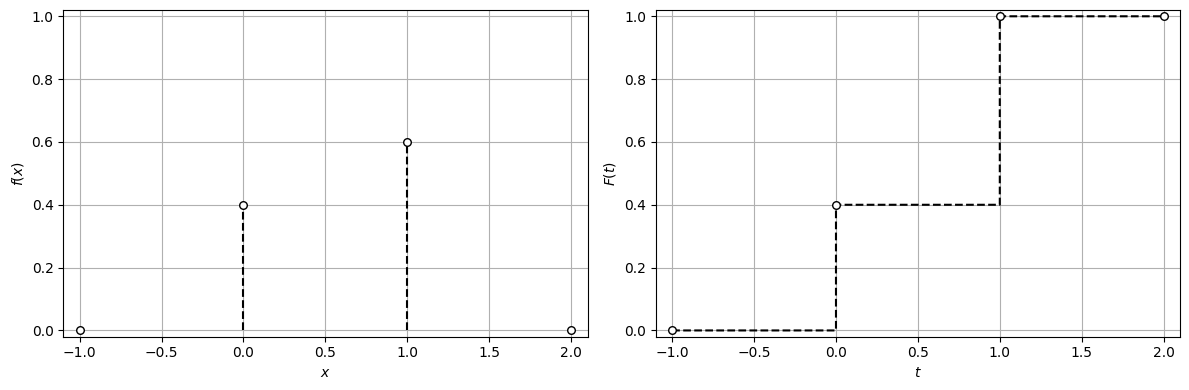

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].vlines(D, 0, f, colors='k', linestyles='--')
axs[0].scatter(D, f, marker='o', s=30, color='white', edgecolor='black', zorder=3)
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$f(x)$')
axs[0].axis([-1.1, 2.1, -0.02, 1.02])
axs[0].grid(True)
axs[1].step(t, F, 'k--', where='post')
axs[1].scatter(D, np.cumsum(f), marker='o', s=30, facecolors='w', edgecolors='black', zorder=3)
axs[1].set_xlabel('$t$')
axs[1].set_ylabel('$F(t)$')
axs[1].axis([-1.1, 2.1, -0.02, 1.02])
axs[1].grid(True)
plt.tight_layout()
plt.show()